In [54]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from category_encoders import TargetEncoder 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
from xgboost import XGBRegressor
import warnings
warnings.filterwarnings('ignore')

In [55]:
def data_loader(path):
    df = pd.read_csv(path)
    return df

path = '../data/raw/HomeTehran.csv'
df = data_loader(path=path)

df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


In [56]:
df.shape

(3479, 8)

In [57]:
df.drop('Price(USD)' , axis=1 , inplace=True)

In [58]:
df.shape

(3479, 7)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Area       3479 non-null   object 
 1   Room       3479 non-null   int64  
 2   Parking    3479 non-null   bool   
 3   Warehouse  3479 non-null   bool   
 4   Elevator   3479 non-null   bool   
 5   Address    3456 non-null   object 
 6   Price      3479 non-null   float64
dtypes: bool(3), float64(1), int64(1), object(2)
memory usage: 119.0+ KB


In [60]:
df.describe()

,Room,Price
count,3479.000000,3.479000e+03
mean,2.079908,5.359023e+09
std,0.758275,8.099935e+09
min,0.000000,3.600000e+06
25%,2.000000,1.418250e+09
50%,2.000000,2.900000e+09
75%,2.000000,6.000000e+09
max,5.000000,9.240000e+10


In [61]:
df.isna().sum()

Area          0
Room          0
Parking       0
Warehouse     0
Elevator      0
Address      23
Price         0
dtype: int64

In [62]:
df.duplicated().sum()

208

In [63]:
df['Area'] = df['Area'].astype(str).str.replace(',' ,'').str.strip().astype('int64')
df['Elevator'] = df['Elevator'].astype('int8')
df['Warehouse'] = df['Warehouse'].astype('int8')
df['Room'] = df['Room'].astype('int8')
df['Parking'] = df['Parking'].astype('int8')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Area       3479 non-null   int64  
 1   Room       3479 non-null   int8   
 2   Parking    3479 non-null   int8   
 3   Warehouse  3479 non-null   int8   
 4   Elevator   3479 non-null   int8   
 5   Address    3456 non-null   object 
 6   Price      3479 non-null   float64
dtypes: float64(1), int64(1), int8(4), object(1)
memory usage: 95.3+ KB


In [64]:
df.columns

Index(['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address', 'Price'], dtype='object')

In [65]:
df.describe()

,Area,Room,Parking,Warehouse,Elevator,Price
count,3.479000e+03,3479.000000,3479.000000,3479.000000,3479.000000,3.479000e+03
mean,8.744000e+06,2.079908,0.847945,0.914631,0.787295,5.359023e+09
std,3.167266e+08,0.758275,0.359126,0.279471,0.409279,8.099935e+09
min,3.000000e+01,0.000000,0.000000,0.000000,0.000000,3.600000e+06
25%,6.900000e+01,2.000000,1.000000,1.000000,1.000000,1.418250e+09
50%,9.000000e+01,2.000000,1.000000,1.000000,1.000000,2.900000e+09
75%,1.200000e+02,2.000000,1.000000,1.000000,1.000000,6.000000e+09
max,1.616000e+10,5.000000,1.000000,1.000000,1.000000,9.240000e+10


In [66]:
df[df['Area'] > 900]

,Area,Room,Parking,Warehouse,Elevator,Address,Price
570,3310000000,2,1,1,1,Ostad Moein,3.310000e+09
709,16160000000,3,1,1,1,Pasdaran,1.616000e+10
807,1000,2,1,1,0,Damavand,7.000000e+09
1604,8400000000,2,1,1,1,Gheitarieh,8.700000e+09
1694,929,5,1,1,0,Zafar,8.000000e+10
2171,3600,2,0,0,0,Shahryar,9.720000e+09
2802,2550000000,2,1,1,1,Central Janatabad,2.550000e+09


In [67]:
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price
0,63,1,1,1,1,Shahran,1.850000e+09
1,60,1,1,1,1,Shahran,1.850000e+09
2,79,2,1,1,1,Pardis,5.500000e+08
3,95,2,1,1,1,Shahrake Qods,9.025000e+08
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09
...,...,...,...,...,...,...,...
3474,86,2,1,1,1,Southern Janatabad,3.500000e+09
3475,83,2,1,1,1,Niavaran,6.800000e+09
3476,75,2,0,0,0,Parand,3.650000e+08
3477,105,2,1,1,1,Dorous,5.600000e+09


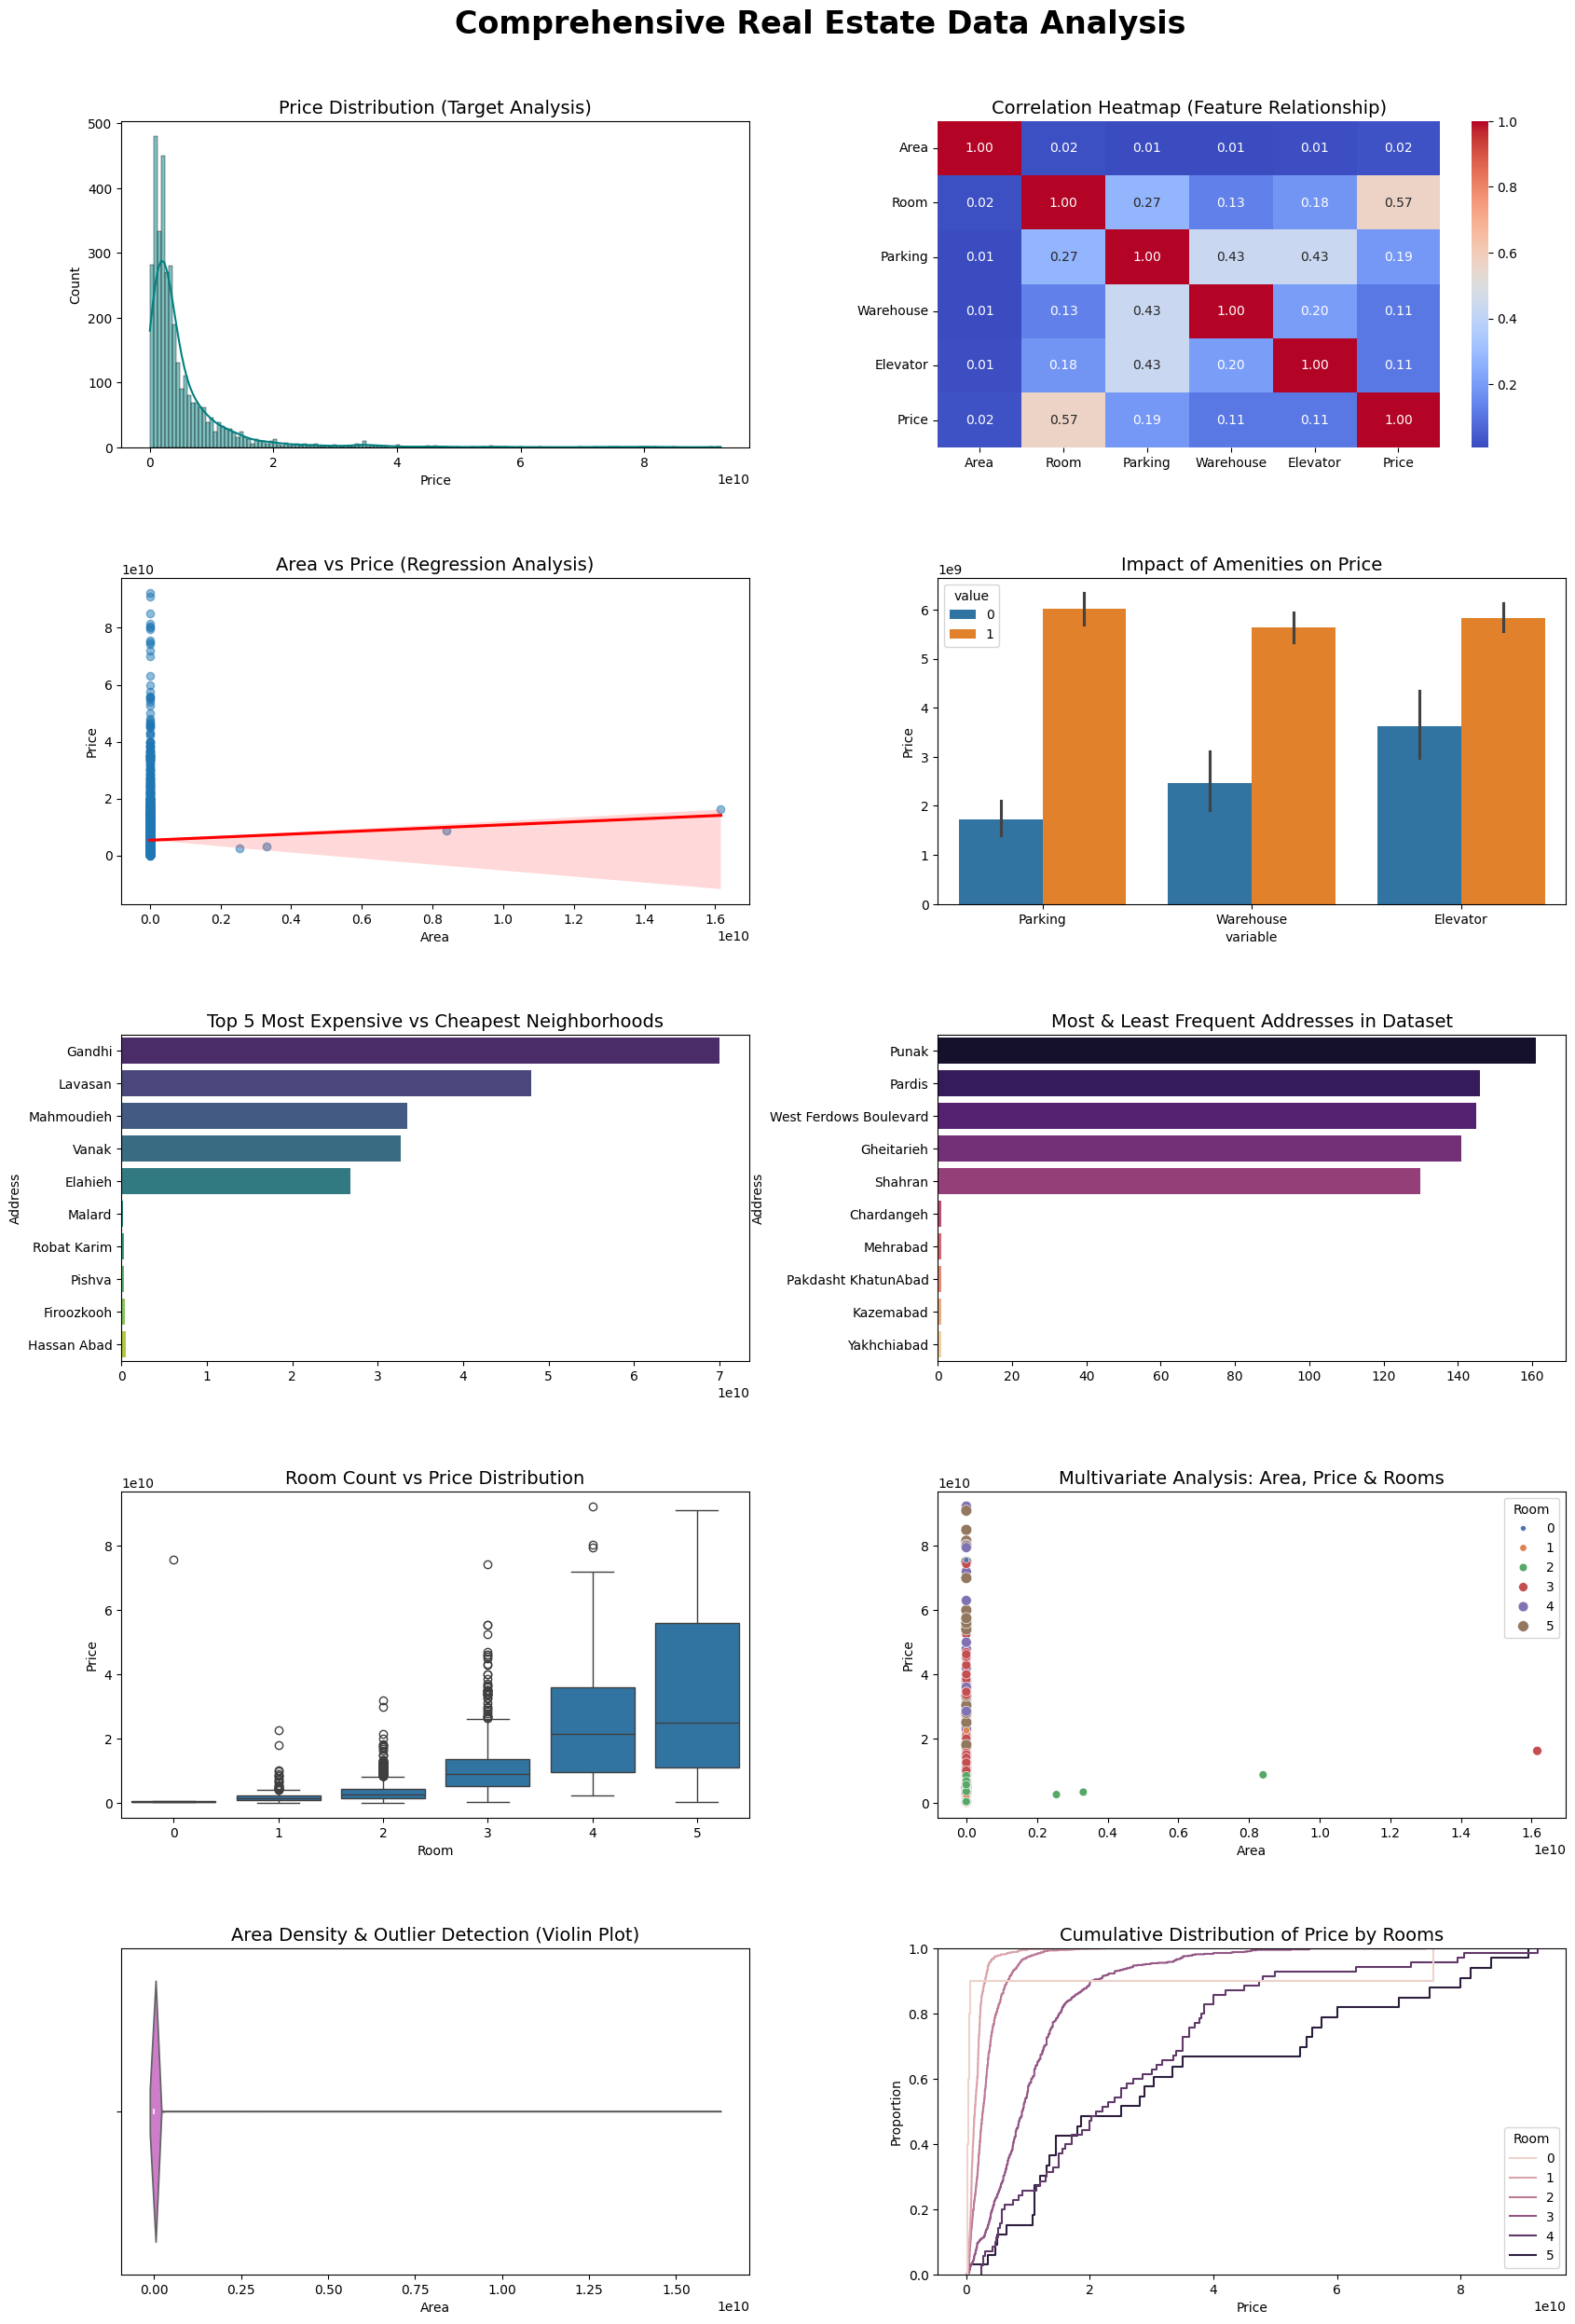

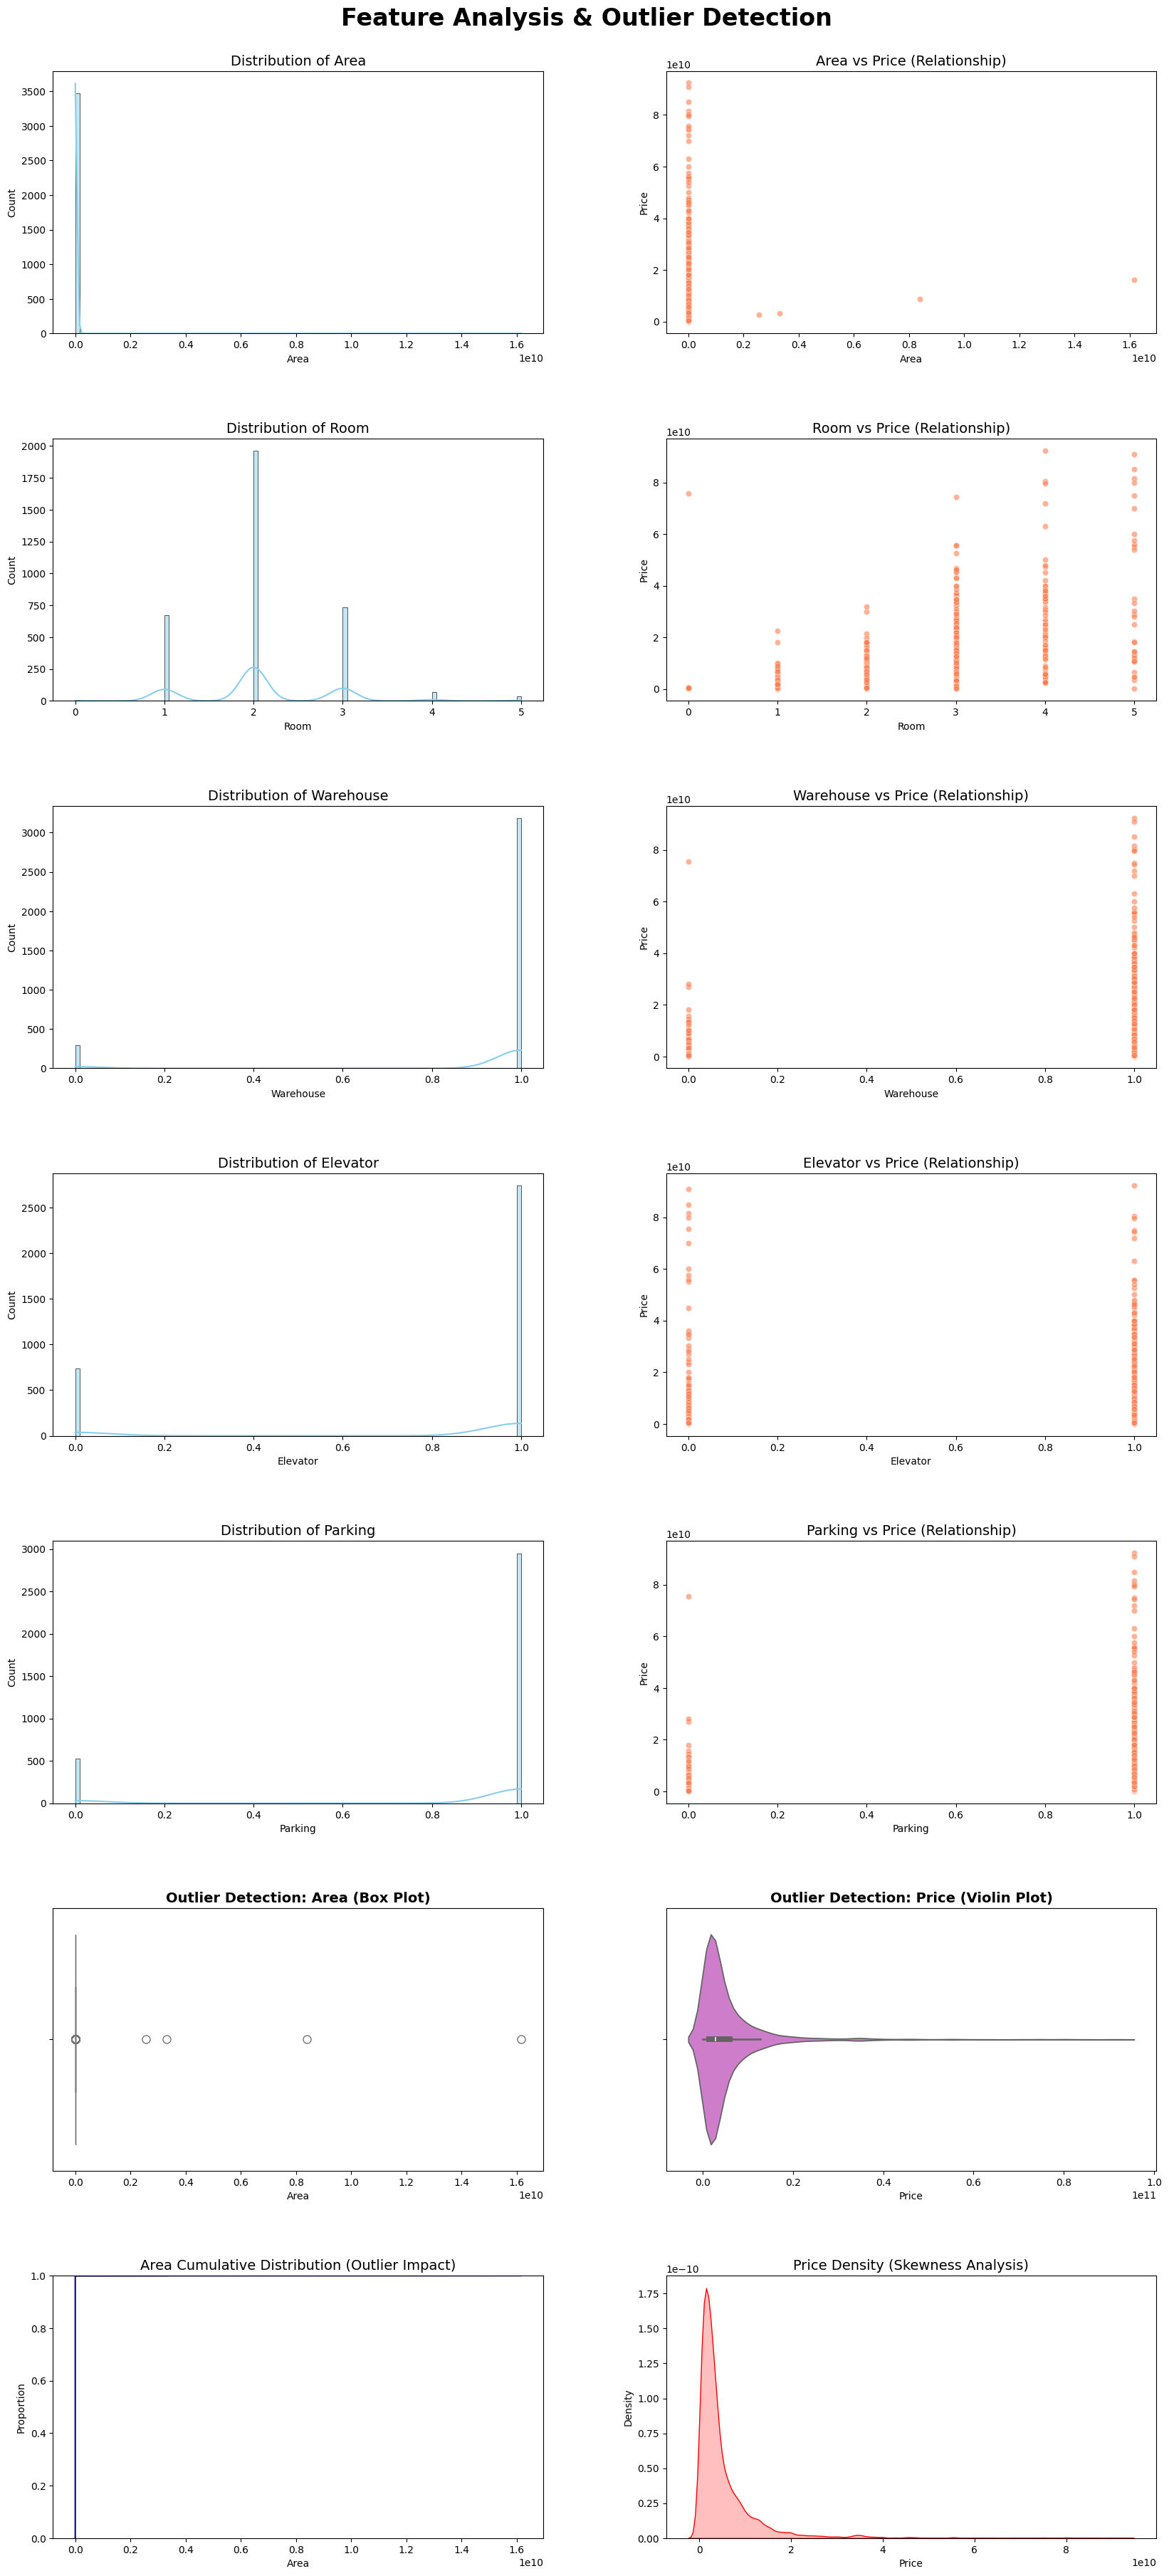

In [68]:
def data_visualization(df):
    
    fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(20, 30))
    fig.subplots_adjust(hspace=0.4, wspace=0.3)
    fig.suptitle('Comprehensive Real Estate Data Analysis', fontsize=24, fontweight='bold', y=0.92)

    sns.histplot(df['Price'], kde=True, ax=axes[0, 0], color='teal')
    axes[0, 0].set_title('Price Distribution (Target Analysis)', fontsize=14)

    corr = df.select_dtypes(include=[np.number]).corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0, 1])
    axes[0, 1].set_title('Correlation Heatmap (Feature Relationship)', fontsize=14)

    sns.regplot(data=df, x='Area', y='Price', ax=axes[1, 0], scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    axes[1, 0].set_title('Area vs Price (Regression Analysis)', fontsize=14)

    binary_features = ['Parking', 'Warehouse', 'Elevator']
    melted_df = df.melt(id_vars='Price', value_vars=binary_features)
    sns.barplot(data=melted_df, x='variable', y='Price', hue='value', ax=axes[1, 1])
    axes[1, 1].set_title('Impact of Amenities on Price', fontsize=14)

    top_expensive = df.groupby('Address')['Price'].mean().sort_values(ascending=False).head(5)
    top_cheapest = df.groupby('Address')['Price'].mean().sort_values(ascending=True).head(5)
    address_stats = pd.concat([top_expensive, top_cheapest])
    sns.barplot(x=address_stats.values, y=address_stats.index, ax=axes[2, 0], palette='viridis')
    axes[2, 0].set_title('Top 5 Most Expensive vs Cheapest Neighborhoods', fontsize=14)

    address_counts = df['Address'].value_counts()
    top_freq = pd.concat([address_counts.head(5), address_counts.tail(5)])
    sns.barplot(x=top_freq.values, y=top_freq.index, ax=axes[2, 1], palette='magma')
    axes[2, 1].set_title('Most & Least Frequent Addresses in Dataset', fontsize=14)

    sns.boxplot(data=df, x='Room', y='Price', ax=axes[3, 0])
    axes[3, 0].set_title('Room Count vs Price Distribution', fontsize=14)

    sns.scatterplot(data=df, x='Area', y='Price', hue='Room', size='Room', palette='deep', ax=axes[3, 1])
    axes[3, 1].set_title('Multivariate Analysis: Area, Price & Rooms', fontsize=14)

    sns.violinplot(data=df, x='Area', ax=axes[4, 0], color='orchid')
    axes[4, 0].set_title('Area Density & Outlier Detection (Violin Plot)', fontsize=14)

    sns.ecdfplot(data=df, x='Price', hue='Room', ax=axes[4, 1])
    axes[4, 1].set_title('Cumulative Distribution of Price by Rooms', fontsize=14)

    
    features = ['Area', 'Room', 'Warehouse', 'Elevator', 'Parking']
    
    fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(20, 45))
    fig.subplots_adjust(hspace=0.4, wspace=0.25)
    fig.suptitle('Feature Analysis & Outlier Detection', fontsize=24, fontweight='bold', y=0.9)

    for i, col in enumerate(features):
        sns.histplot(df[col], kde=True, ax=axes[i, 0],bins=100, color='skyblue')
        axes[i, 0].set_title(f'Distribution of {col}', fontsize=14)
        
        sns.scatterplot(data=df, x=col, y='Price', ax=axes[i, 1], color='coral', alpha=0.6)
        axes[i, 1].set_title(f'{col} vs Price (Relationship)', fontsize=14)

    
    sns.boxplot(x=df['Area'], ax=axes[5, 0], color='lightgreen', fliersize=8)
    axes[5, 0].set_title('Outlier Detection: Area (Box Plot)', fontsize=14, fontweight='bold')

    sns.violinplot(x=df['Price'], ax=axes[5, 1], color='orchid')
    axes[5, 1].set_title('Outlier Detection: Price (Violin Plot)', fontsize=14, fontweight='bold')

    sns.ecdfplot(data=df, x='Area', ax=axes[6, 0], color='darkblue')
    axes[6, 0].set_title('Area Cumulative Distribution (Outlier Impact)', fontsize=14)

    sns.kdeplot(data=df, x='Price', fill=True, bw_adjust=0.5, ax=axes[6, 1], color='red')
    axes[6, 1].set_title('Price Density (Skewness Analysis)', fontsize=14)

    
    return fig

fig = data_visualization(df)
plt.show()


In [69]:
df['Room'].value_counts().sort_index()

Room
0      10
1     673
2    1961
3     732
4      70
5      33
Name: count, dtype: int64

In [70]:
percentiles = [0.15 , 0.25 , 0.35 , 0.50, 0.75, 0.90, 0.95, 0.99]
df['Price'].quantile(percentiles).round()

0.15    8.785000e+08
0.25    1.418250e+09
0.35    1.958110e+09
0.50    2.900000e+09
0.75    6.000000e+09
0.90    1.200000e+10
0.95    1.765670e+10
0.99    4.000000e+10
Name: Price, dtype: float64

In [71]:
df1 = df.copy()
df = data_loader(path)
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33
...,...,...,...,...,...,...,...,...
3474,86,2,True,True,True,Southern Janatabad,3.500000e+09,116666.67
3475,83,2,True,True,True,Niavaran,6.800000e+09,226666.67
3476,75,2,False,False,False,Parand,3.650000e+08,12166.67
3477,105,2,True,True,True,Dorous,5.600000e+09,186666.67


In [72]:
df1

,Area,Room,Parking,Warehouse,Elevator,Address,Price
0,63,1,1,1,1,Shahran,1.850000e+09
1,60,1,1,1,1,Shahran,1.850000e+09
2,79,2,1,1,1,Pardis,5.500000e+08
3,95,2,1,1,1,Shahrake Qods,9.025000e+08
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09
...,...,...,...,...,...,...,...
3474,86,2,1,1,1,Southern Janatabad,3.500000e+09
3475,83,2,1,1,1,Niavaran,6.800000e+09
3476,75,2,0,0,0,Parand,3.650000e+08
3477,105,2,1,1,1,Dorous,5.600000e+09


In [73]:
bins = [
    0,
    4000000000,
    10000000000,
    float("inf")
]

labels = [1, 2, 3]

df1["Price_Category"] = pd.cut(
    df["Price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df1['Price_Category'] = df1['Price_Category'].astype('int8')

In [74]:
df1.dropna(inplace=True)
df1.drop_duplicates(inplace=True)

In [75]:
df1.describe()

,Area,Room,Parking,Warehouse,Elevator,Price,Price_Category
count,3.248000e+03,3248.000000,3248.000000,3248.000000,3248.000000,3.248000e+03,3248.000000
mean,9.365872e+06,2.088054,0.845135,0.914101,0.785406,5.478118e+09,1.497537
std,3.277906e+08,0.764716,0.361831,0.280258,0.410603,8.267916e+09,0.715868
min,3.000000e+01,0.000000,0.000000,0.000000,0.000000,3.600000e+06,1.000000
25%,7.000000e+01,2.000000,1.000000,1.000000,1.000000,1.420000e+09,1.000000
50%,9.000000e+01,2.000000,1.000000,1.000000,1.000000,2.977500e+09,1.000000
75%,1.220000e+02,2.000000,1.000000,1.000000,1.000000,6.200000e+09,2.000000
max,1.616000e+10,5.000000,1.000000,1.000000,1.000000,9.240000e+10,3.000000


In [76]:
df1['Price_log'] = np.log10(df['Price'])

In [77]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3248 entries, 0 to 3478
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Area            3248 non-null   int64  
 1   Room            3248 non-null   int8   
 2   Parking         3248 non-null   int8   
 3   Warehouse       3248 non-null   int8   
 4   Elevator        3248 non-null   int8   
 5   Address         3248 non-null   object 
 6   Price           3248 non-null   float64
 7   Price_Category  3248 non-null   int8   
 8   Price_log       3248 non-null   float64
dtypes: float64(2), int64(1), int8(5), object(1)
memory usage: 142.7+ KB


In [78]:
encoding = TargetEncoder(cols=['Address'])
df1['Address_Encoding'] = encoding.fit_transform(
    df1['Address'],
    df1['Price']
)

In [79]:
df1[['Address' , 'Address_Encoding' , 'Price_Category']]

,Address,Address_Encoding,Price_Category
0,Shahran,3.027058e+09,1
1,Shahran,3.027058e+09,1
2,Pardis,7.938730e+08,1
3,Shahrake Qods,9.367641e+08,1
4,Shahrake Gharb,1.183619e+10,2
...,...,...,...
3473,Feiz Garden,3.456825e+09,1
3474,Southern Janatabad,3.230337e+09,1
3475,Niavaran,1.973064e+10,2
3477,Dorous,9.876786e+09,2


In [80]:
df1.describe()

,Area,Room,Parking,Warehouse,Elevator,Price,Price_Category,Price_log,Address_Encoding
count,3.248000e+03,3248.000000,3248.000000,3248.000000,3248.000000,3.248000e+03,3248.000000,3248.000000,3.248000e+03
mean,9.365872e+06,2.088054,0.845135,0.914101,0.785406,5.478118e+09,1.497537,9.470102,5.370791e+09
std,3.277906e+08,0.764716,0.361831,0.280258,0.410603,8.267916e+09,0.715868,0.477990,4.384487e+09
min,3.000000e+01,0.000000,0.000000,0.000000,0.000000,3.600000e+06,1.000000,6.556303,5.363068e+08
25%,7.000000e+01,2.000000,1.000000,1.000000,1.000000,1.420000e+09,1.000000,9.152288,3.027058e+09
50%,9.000000e+01,2.000000,1.000000,1.000000,1.000000,2.977500e+09,1.000000,9.473852,3.767011e+09
75%,1.220000e+02,2.000000,1.000000,1.000000,1.000000,6.200000e+09,2.000000,9.792392,6.946712e+09
max,1.616000e+10,5.000000,1.000000,1.000000,1.000000,9.240000e+10,3.000000,10.965672,2.026186e+10


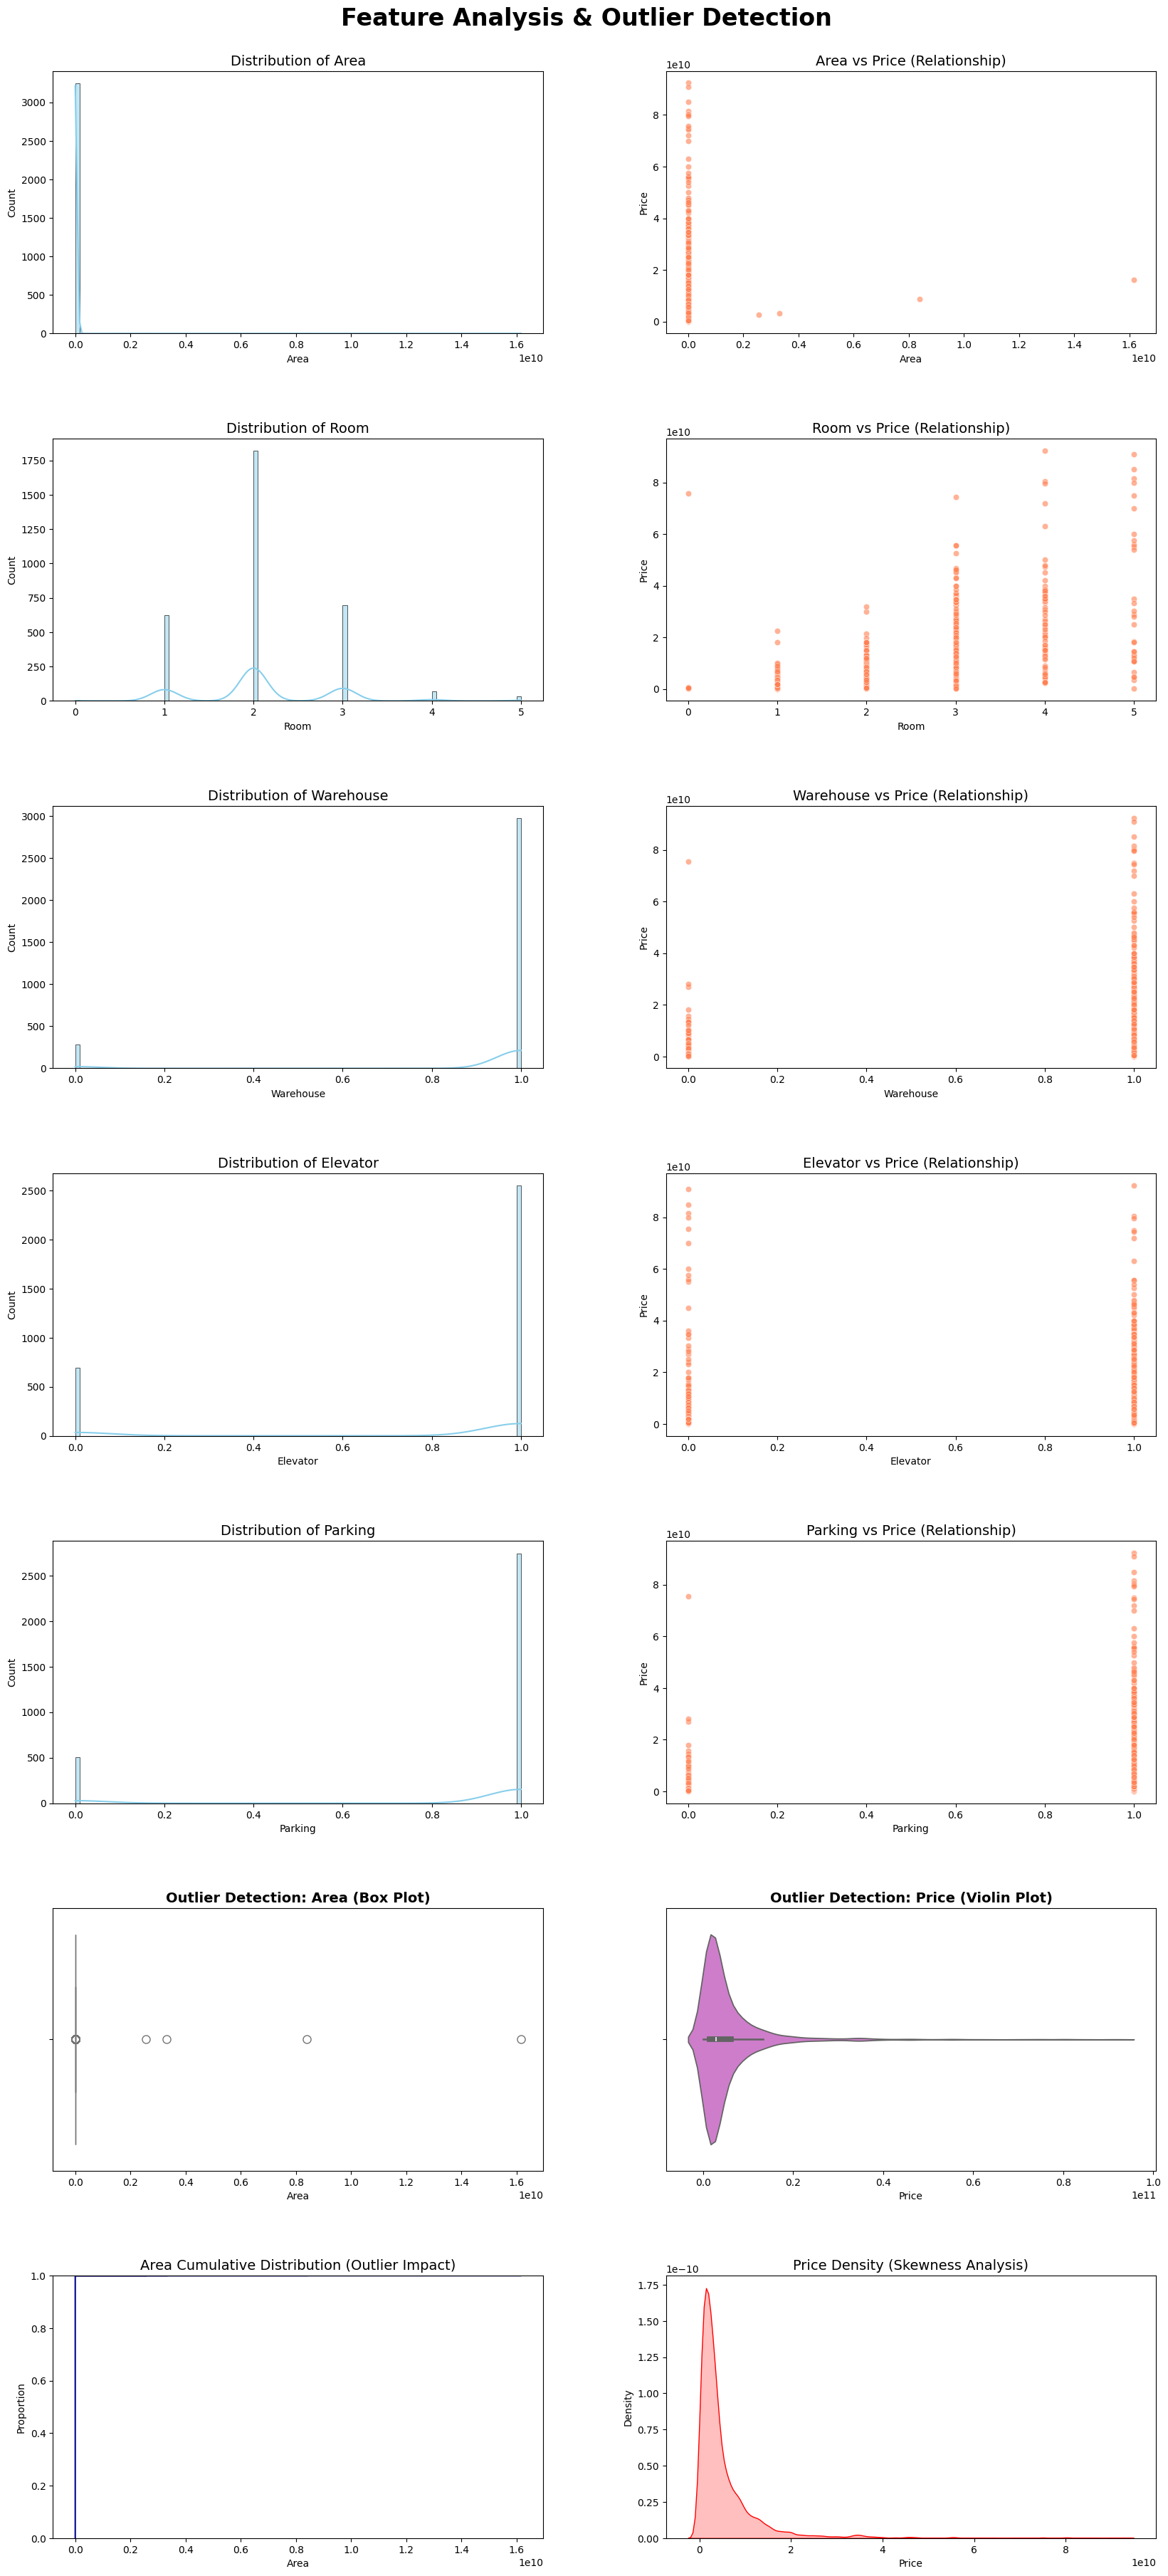

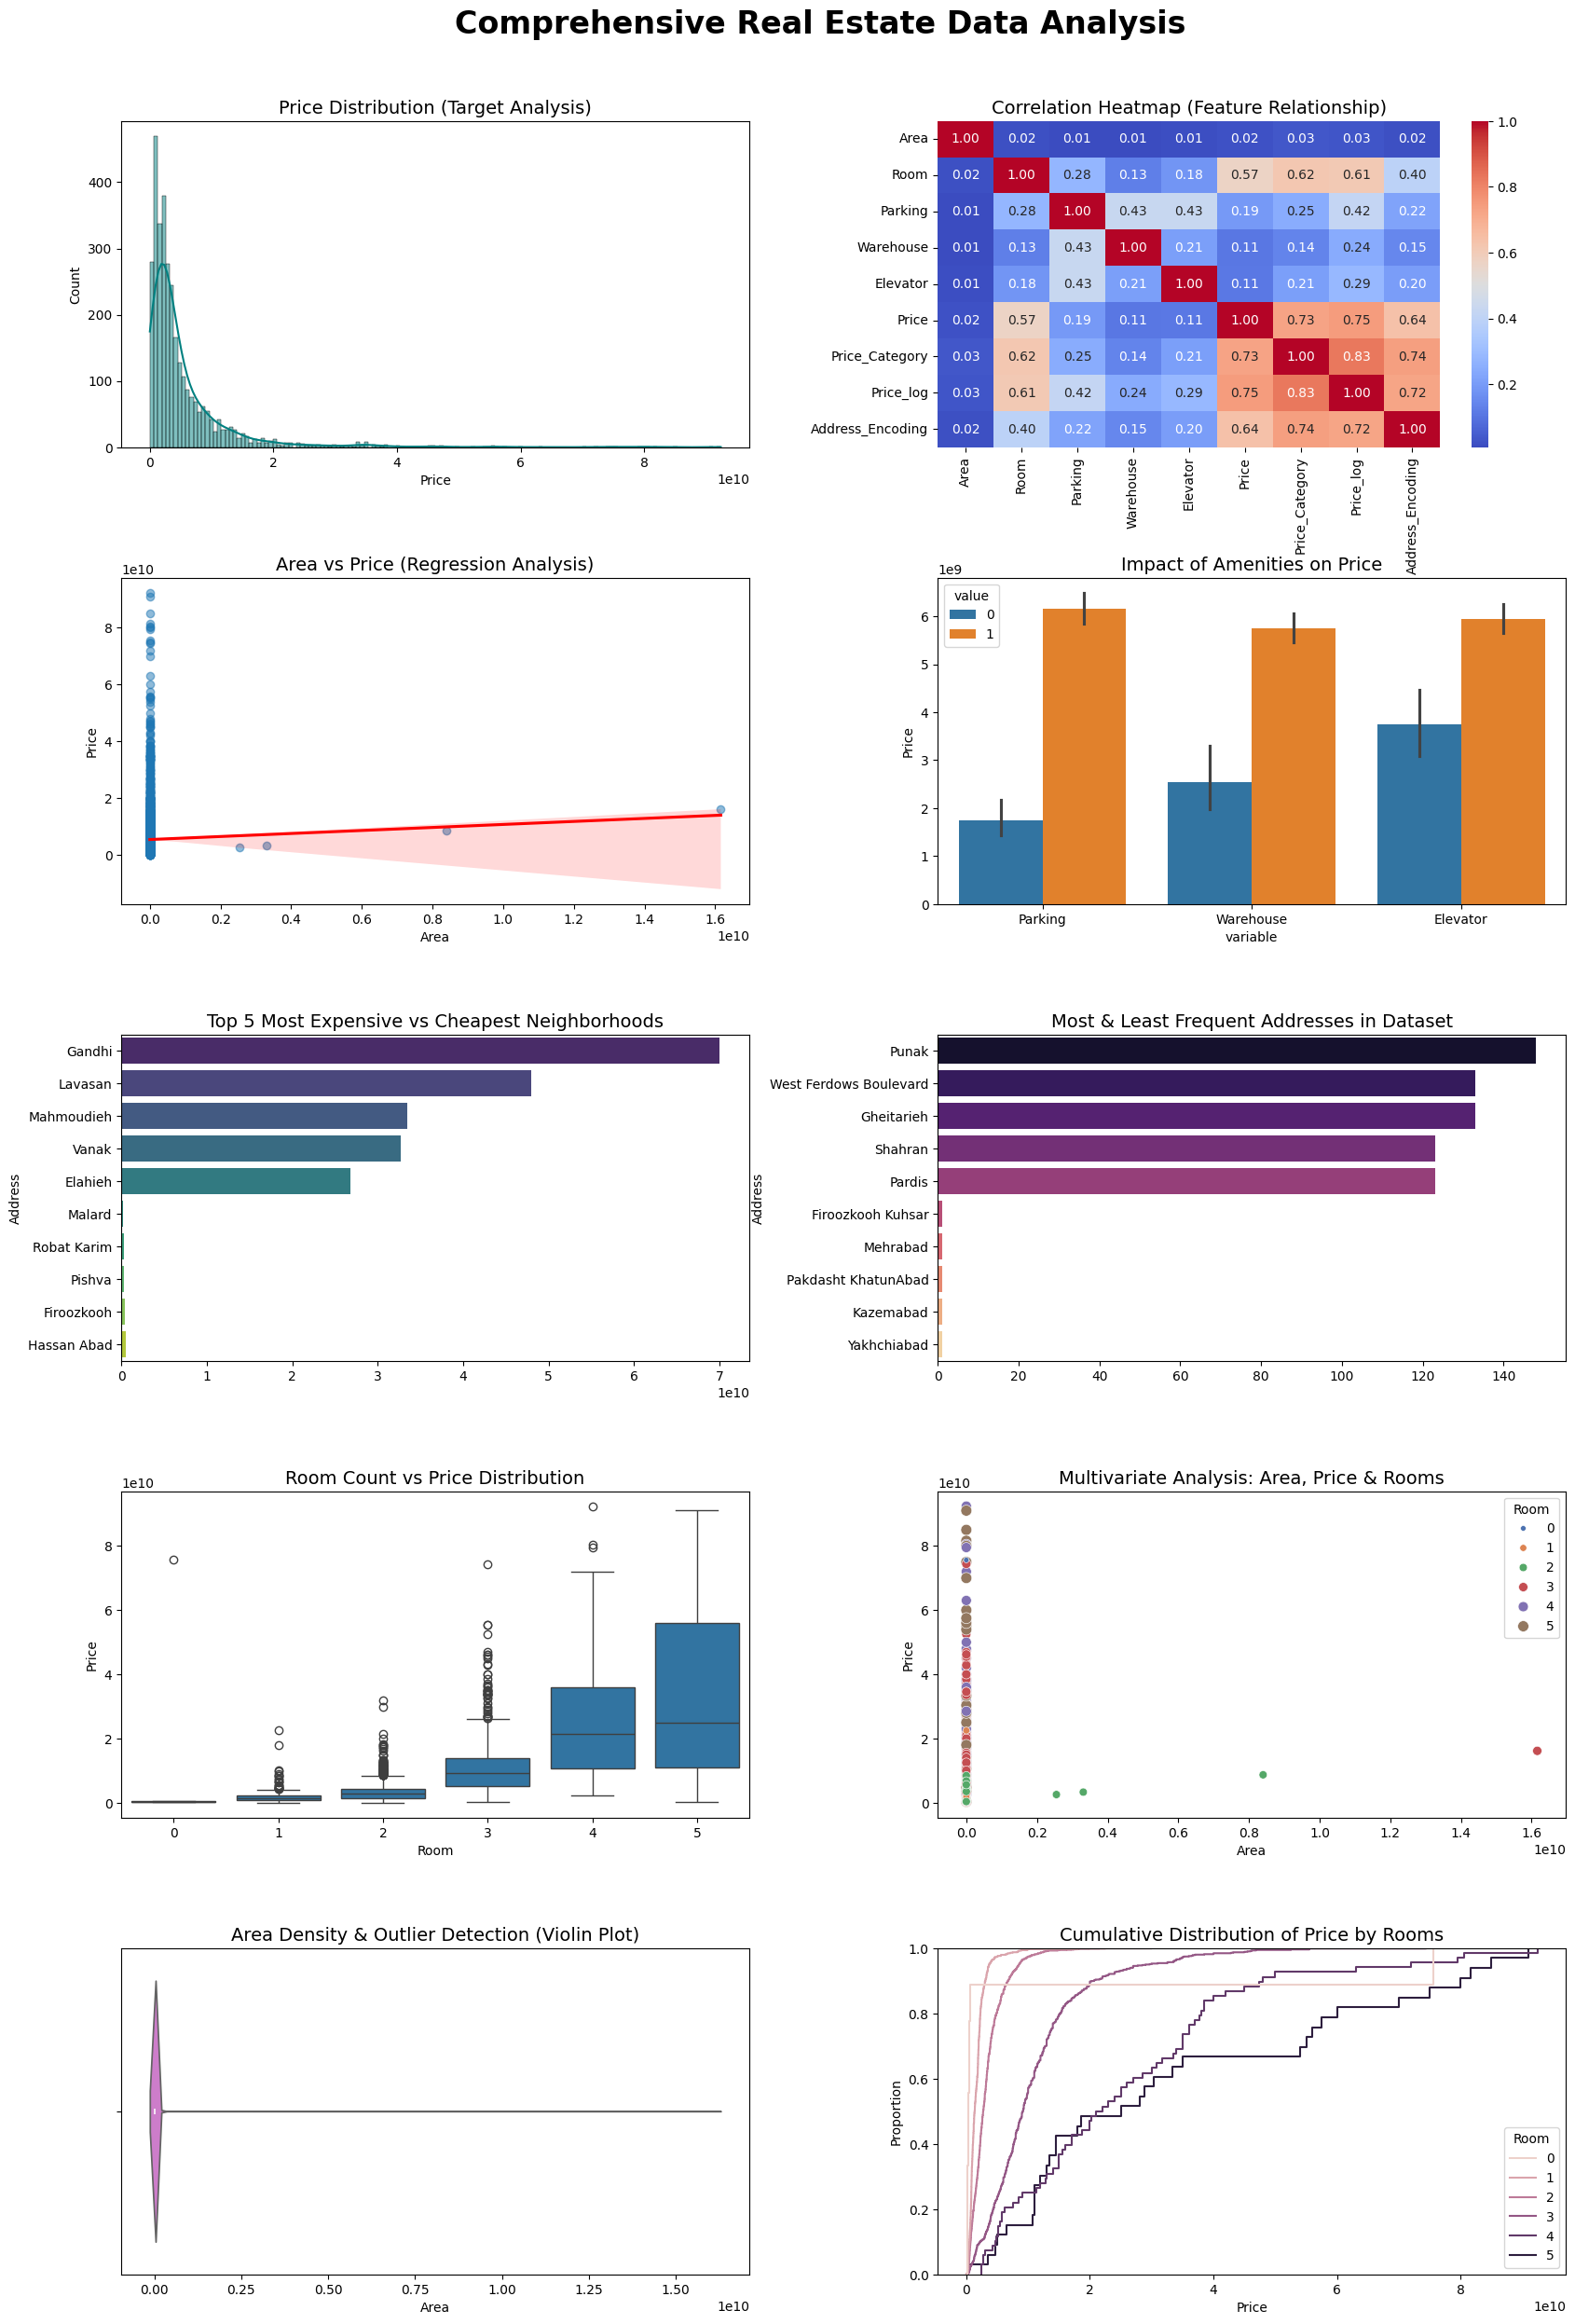

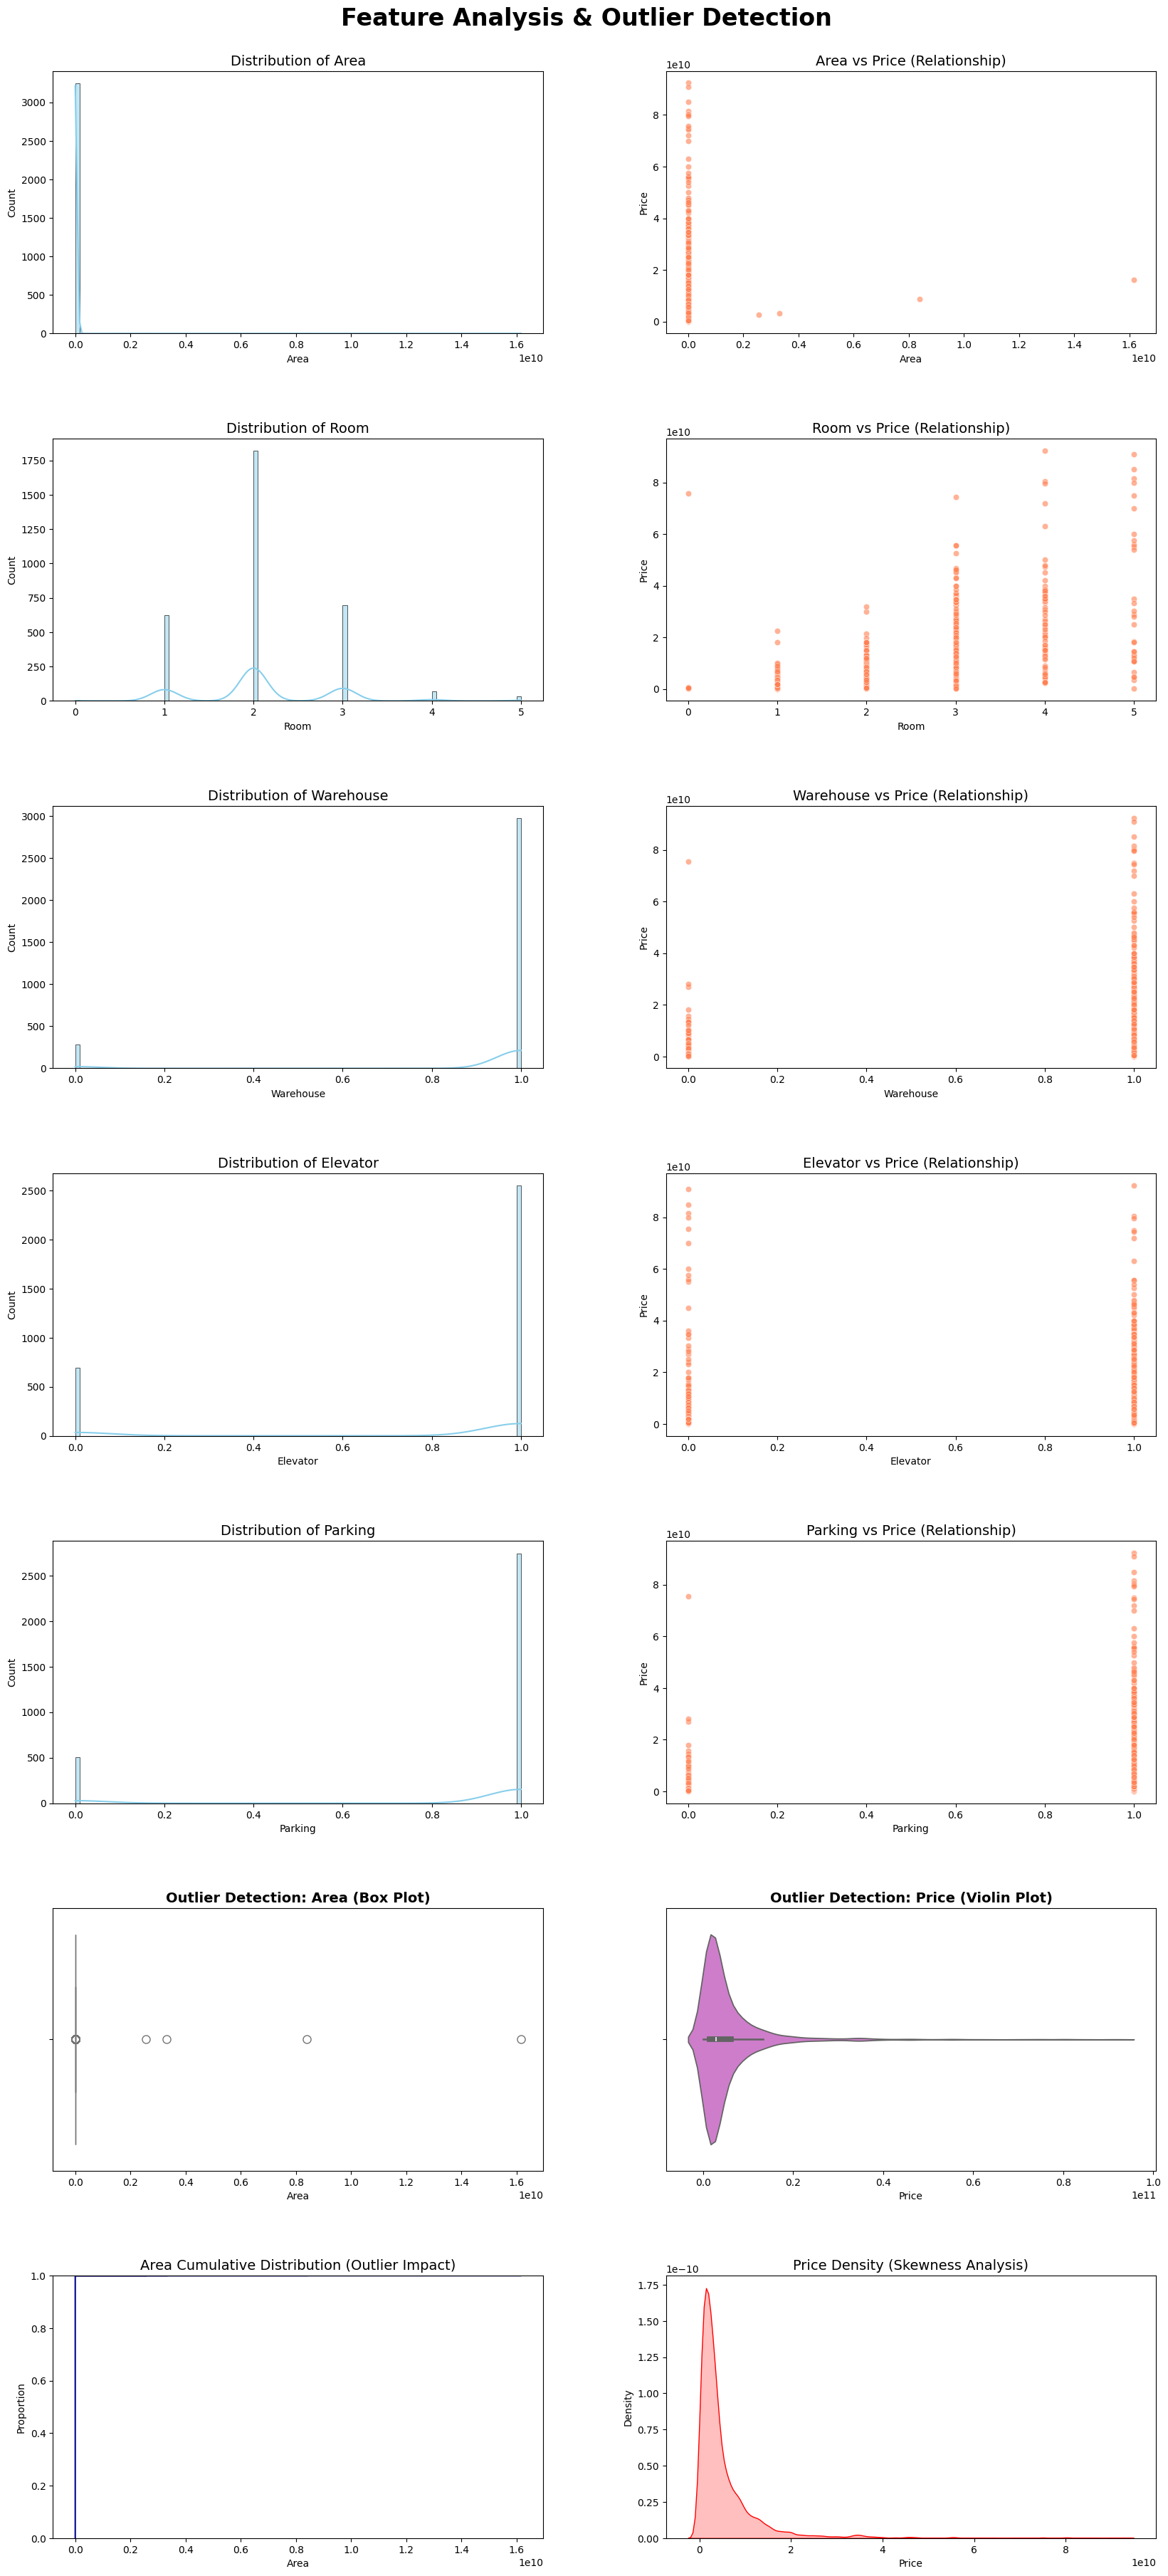

In [81]:
data_visualization(df1)

In [82]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_filtered

In [83]:
df1 = remove_outliers(df1 , 'Area')
df1 = remove_outliers(df1 , 'Price_log')
df1['Price'] = df1['Price_log']
df1.drop('Price_log' , axis=1 , inplace=True)

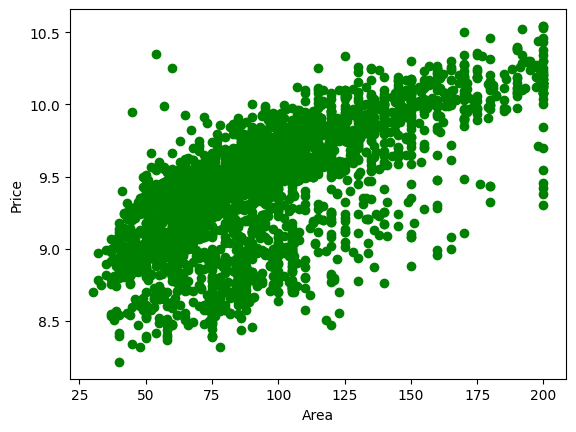

In [84]:
plt.scatter(df1["Area"], df1["Price"], color='Green')
plt.xlabel('Area')
plt.ylabel('Price')
plt.show()

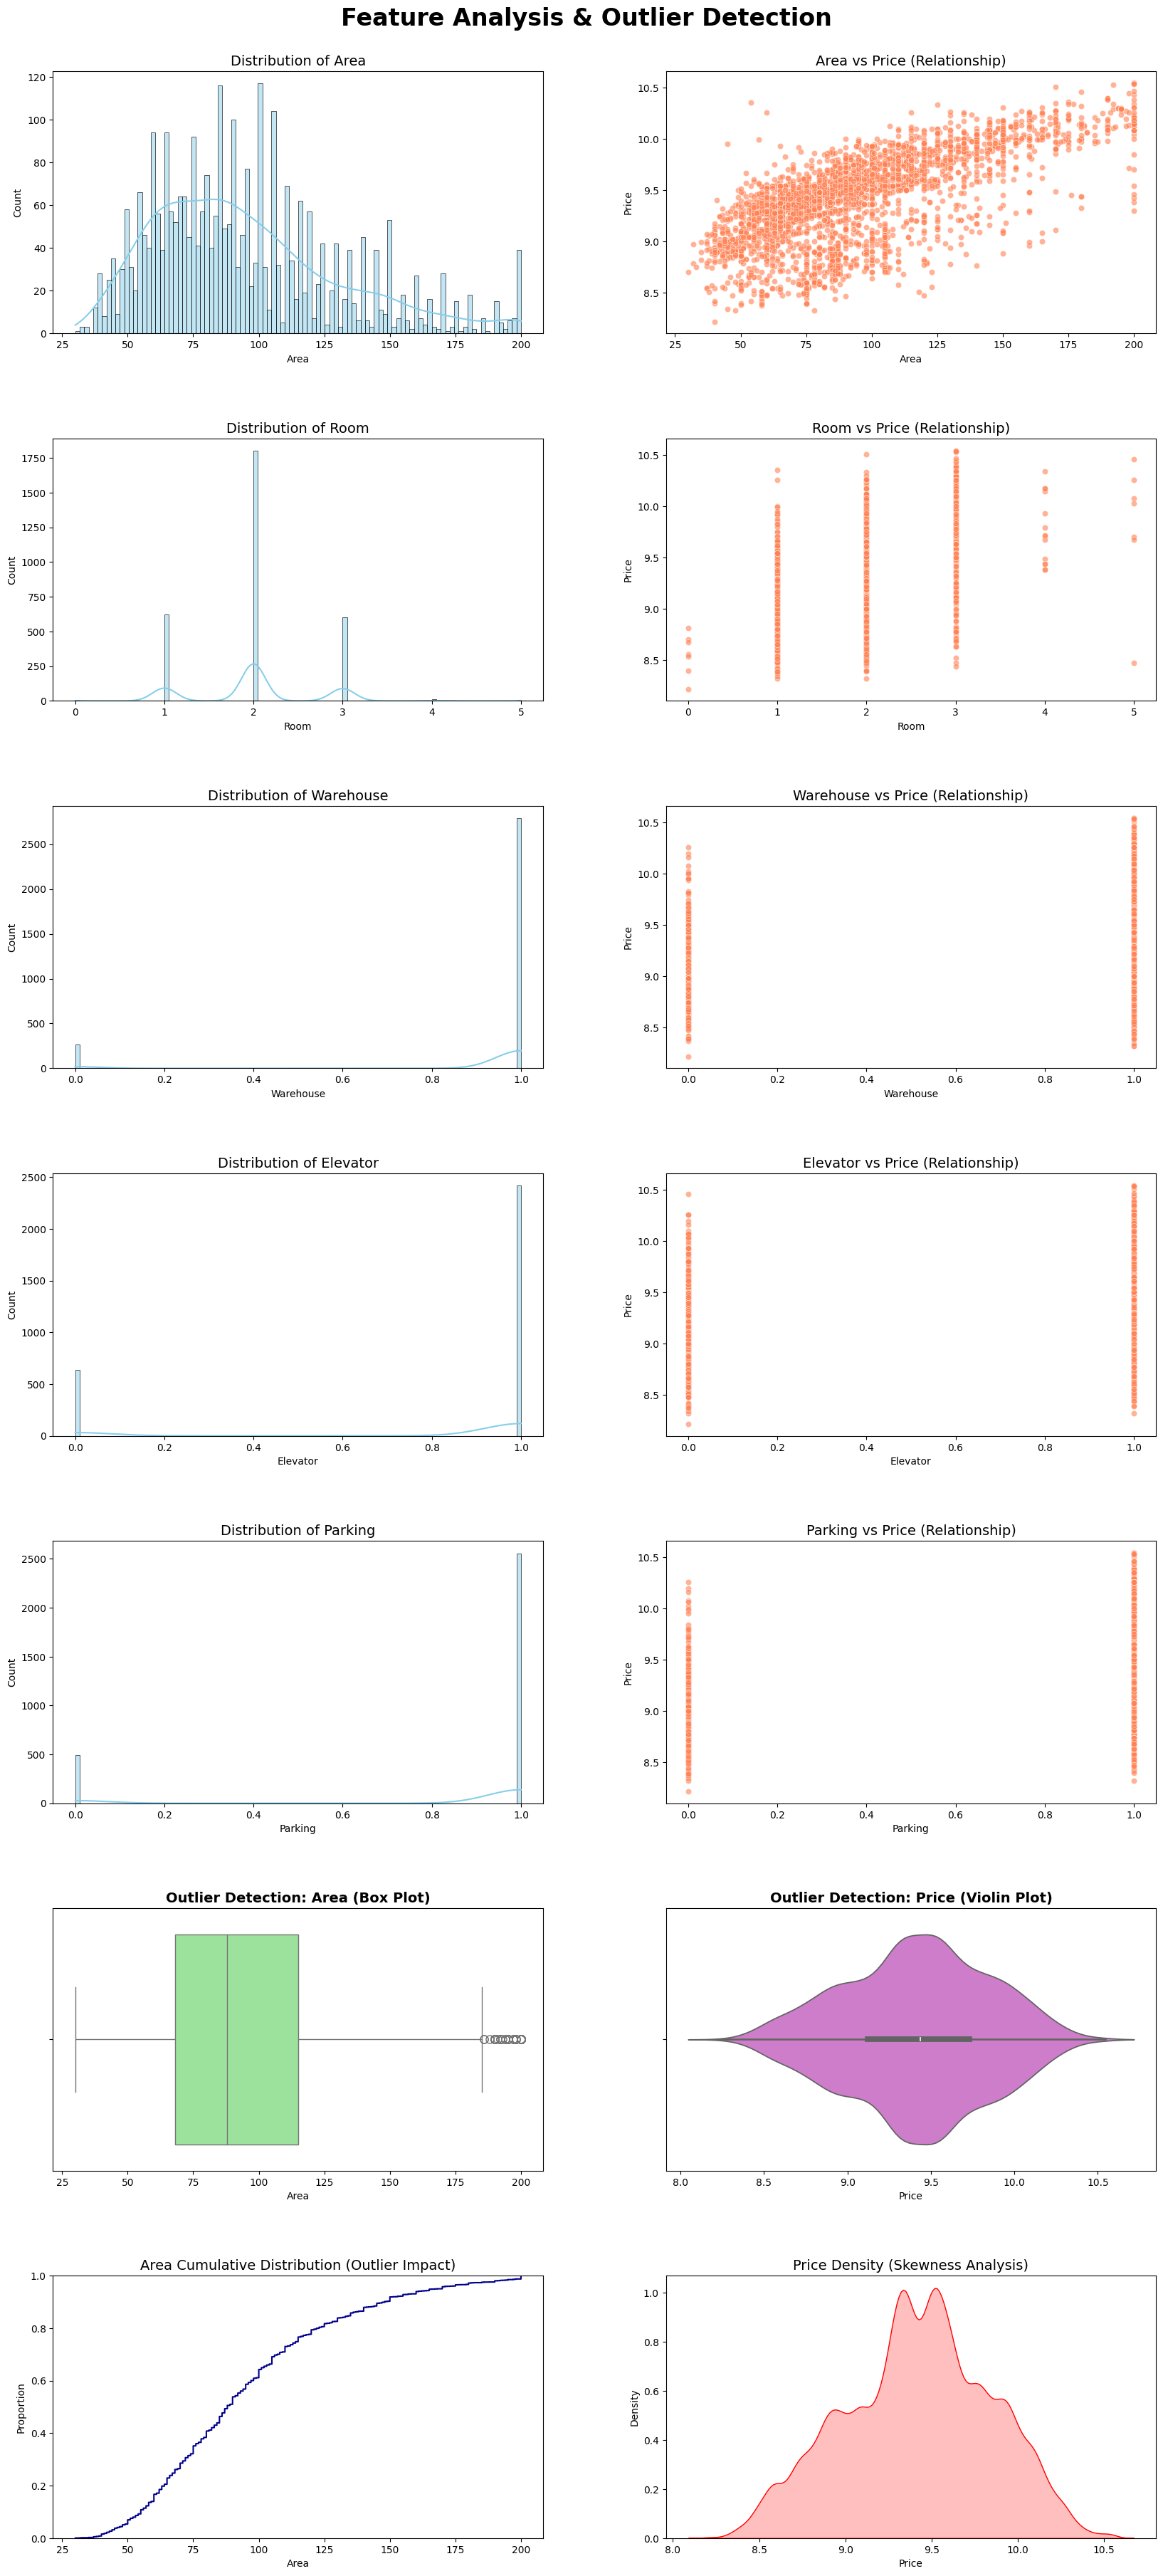

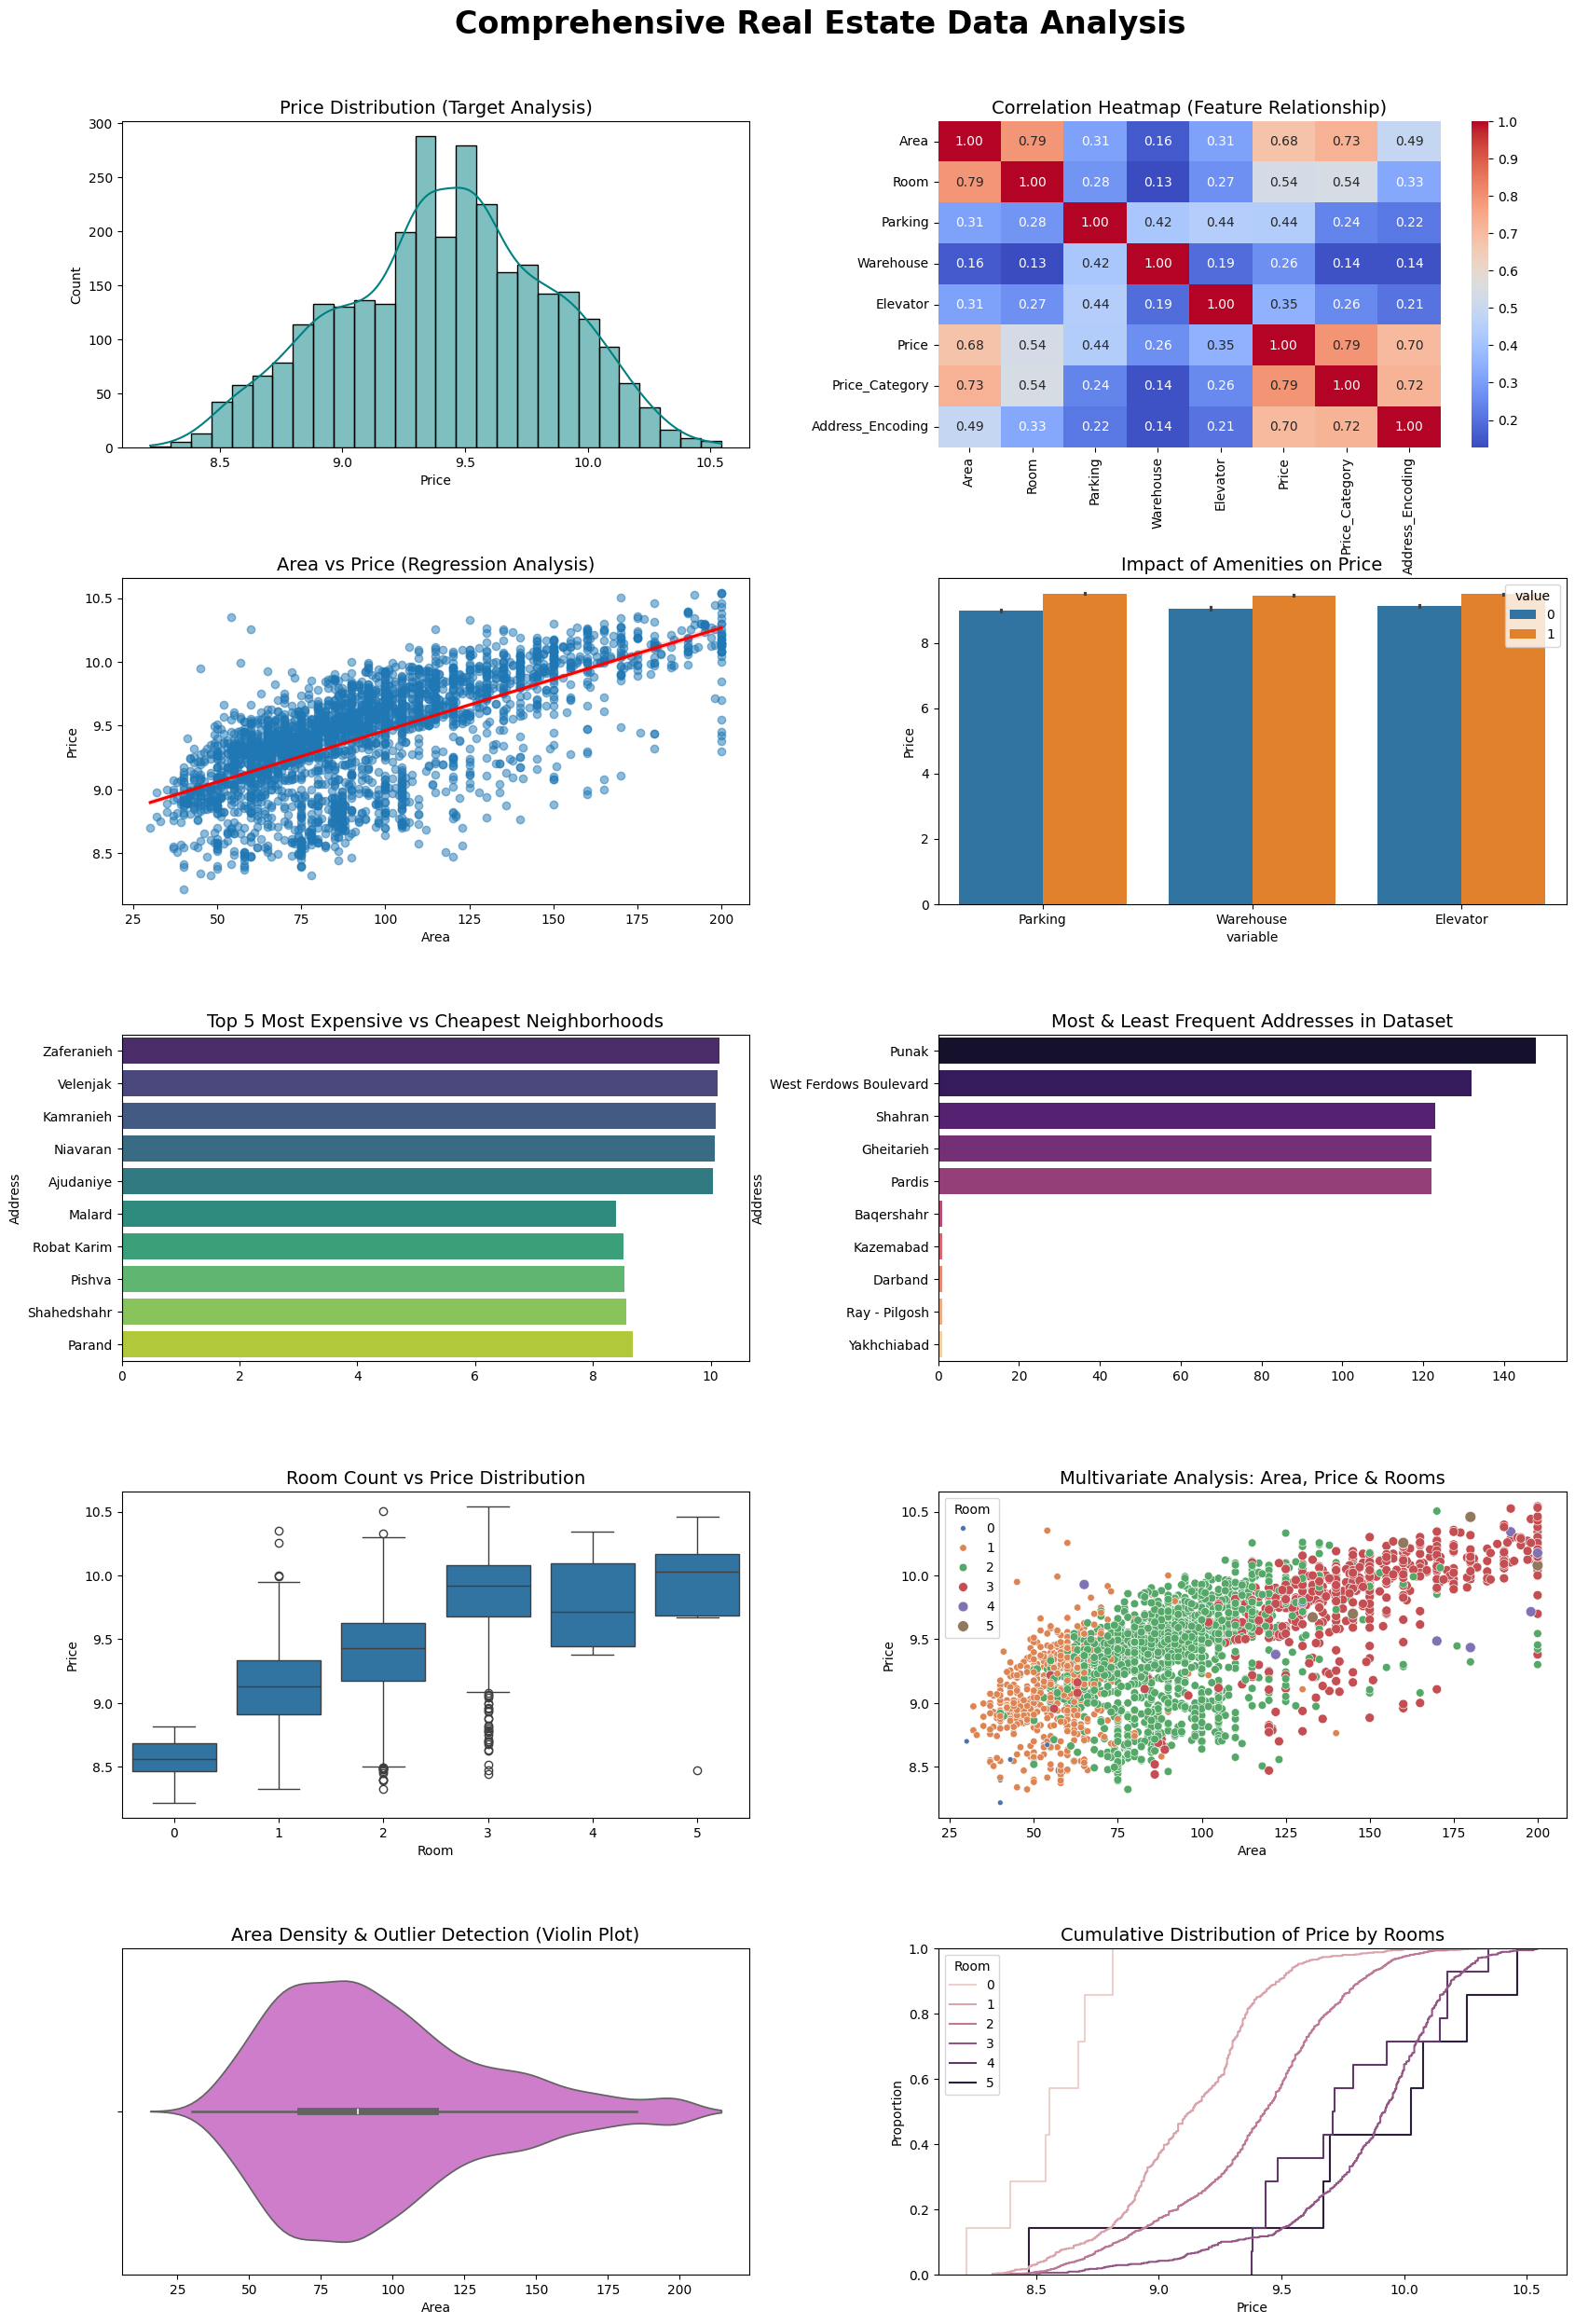

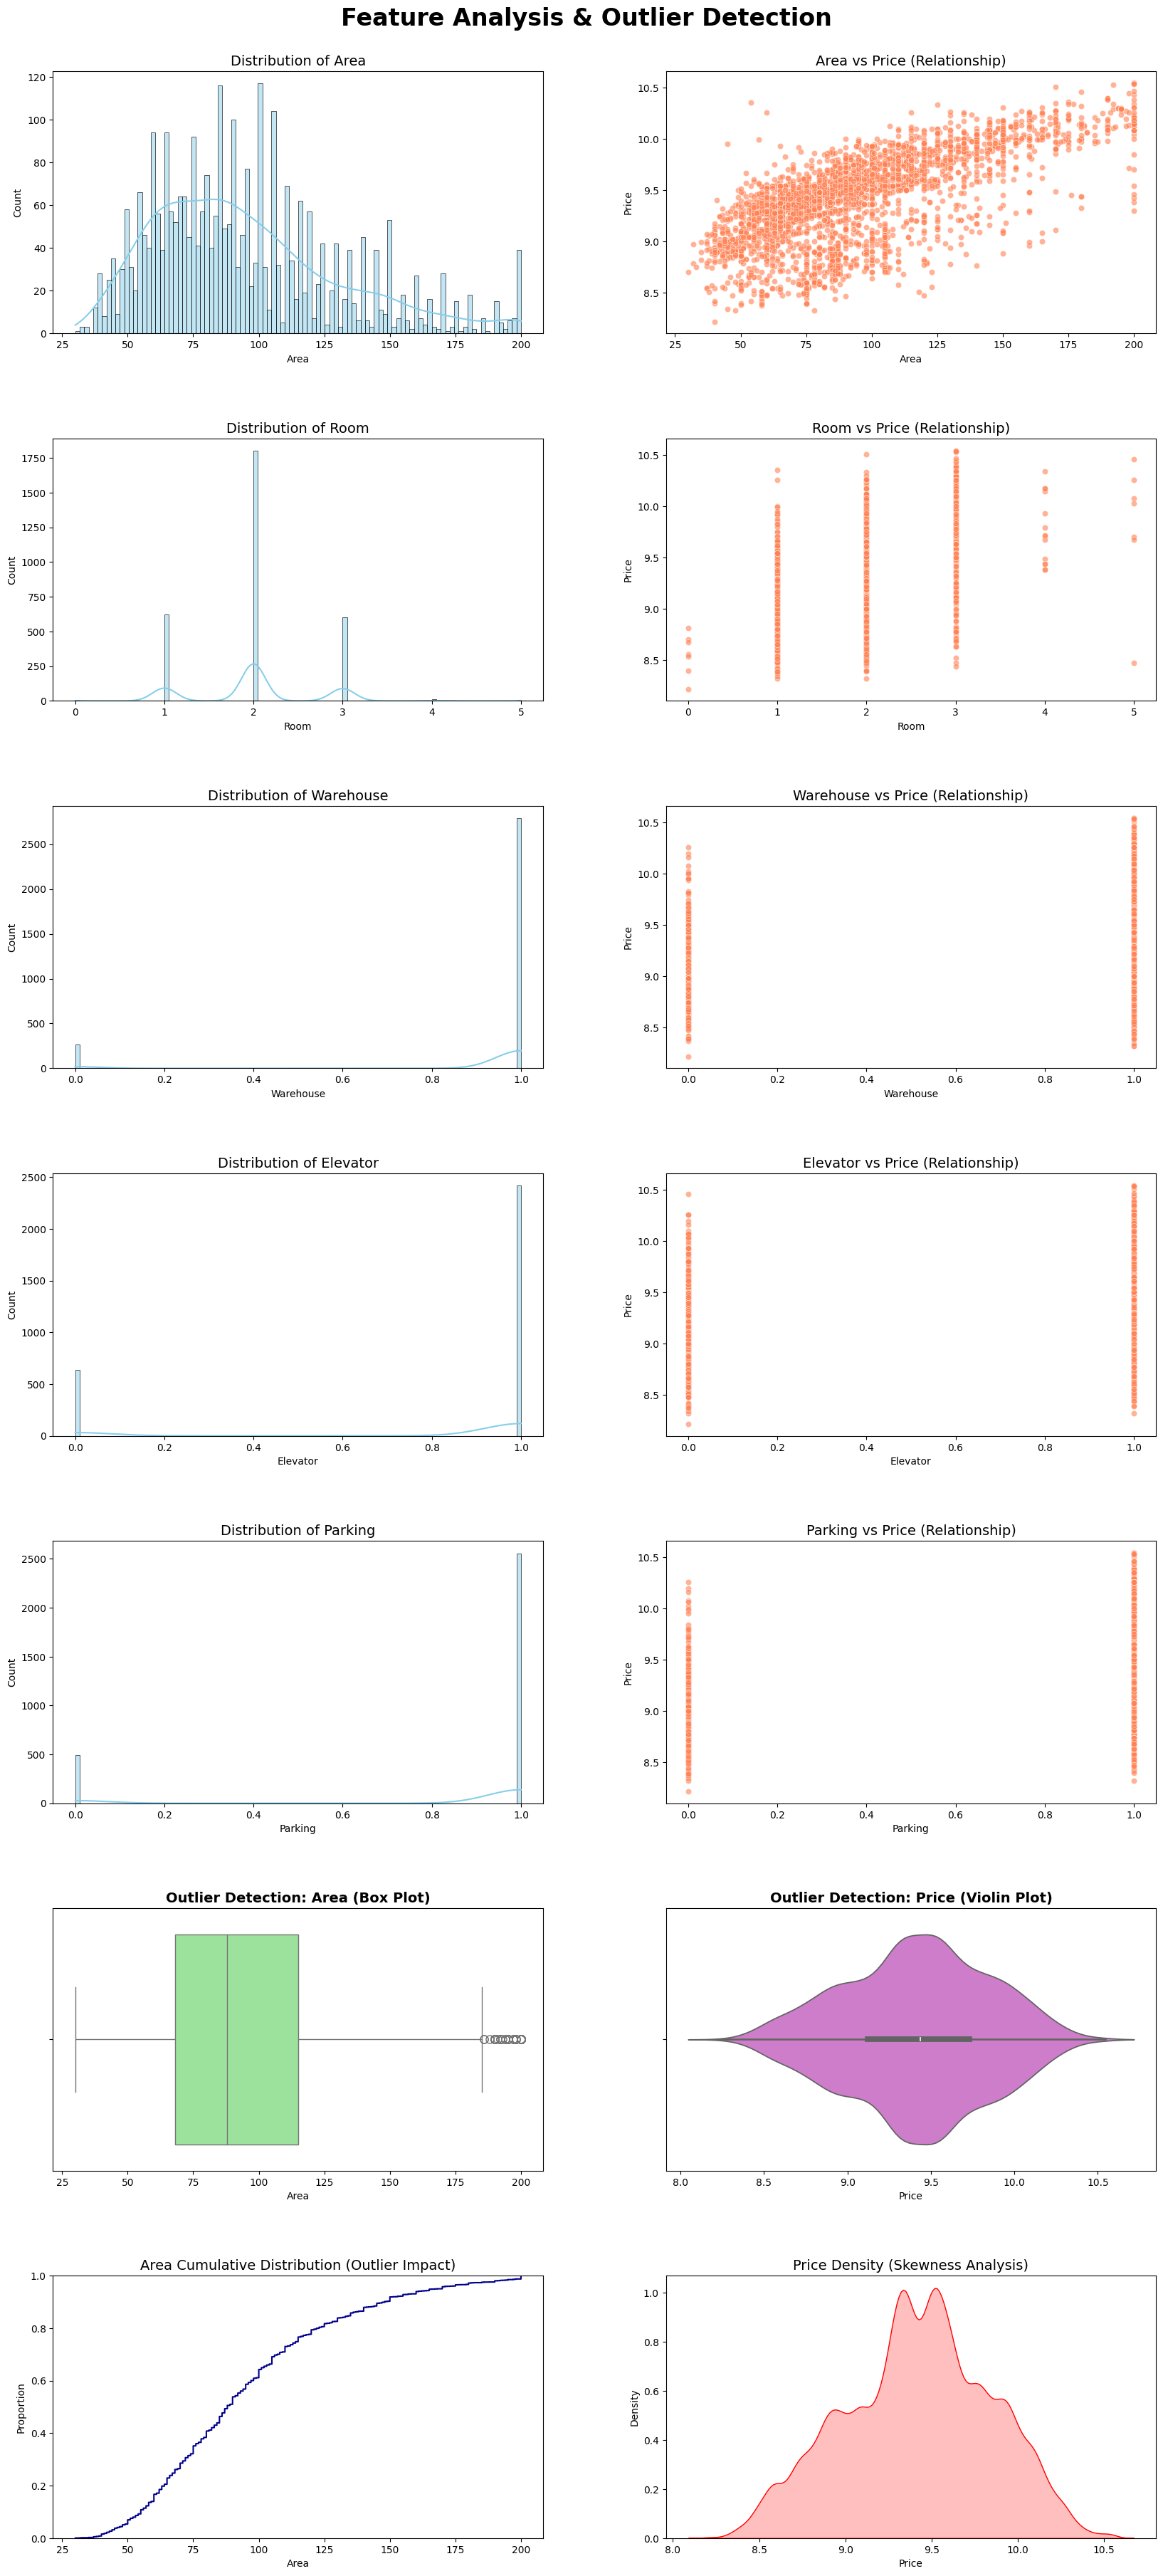

In [85]:
data_visualization(df1)

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   object 
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   object 
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), object(2)
memory usage: 146.2+ KB


In [87]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3051 entries, 0 to 3478
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Area              3051 non-null   int64  
 1   Room              3051 non-null   int8   
 2   Parking           3051 non-null   int8   
 3   Warehouse         3051 non-null   int8   
 4   Elevator          3051 non-null   int8   
 5   Address           3051 non-null   object 
 6   Price             3051 non-null   float64
 7   Price_Category    3051 non-null   int8   
 8   Address_Encoding  3051 non-null   float64
dtypes: float64(2), int64(1), int8(5), object(1)
memory usage: 134.1+ KB


In [88]:
x = df1[['Area' , 'Room' ,'Parking' ,'Warehouse' ,'Elevator' ,'Address_Encoding']]
y = df1['Price']

In [89]:
X_train , X_test , y_train , y_test = train_test_split(x,y ,test_size=0.2 , random_state=42 , shuffle=True)


In [90]:
minmax = MinMaxScaler()
minmax.fit_transform(X_train,y_train)

array([[0.17647059, 0.2       , 1.        , 1.        , 1.        ,
        0.13642554],
       [0.35294118, 0.4       , 1.        , 1.        , 1.        ,
        0.28349999],
       [0.32352941, 0.4       , 1.        , 0.        , 1.        ,
        0.21959877],
       ...,
       [0.68823529, 0.6       , 1.        , 1.        , 1.        ,
        0.35247126],
       [0.32352941, 0.4       , 1.        , 1.        , 1.        ,
        0.13657566],
       [0.44117647, 0.4       , 1.        , 1.        , 1.        ,
        0.01305749]])

In [91]:
model = LinearRegression()
model.fit(X_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[0.,0.,0.,0.,0.,0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Area','Room','Parking','Warehouse','Elevator','Address_Encoding']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.047
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [92]:
y_pred = model.predict(X_test)

In [93]:
def cal(y_test , y_pred):
    mse = mean_squared_error(y_test , y_pred)
    mae = mean_absolute_error(y_test , y_pred)
    r2 = r2_score(y_test , y_pred)

    print(f'mean squared error: {mse}')
    print(f'mean absolute error: {mae}')
    print(f'r2 score: {r2}')

cal(y_test , y_pred)

mean squared error: 0.07780480619240274
mean absolute error: 0.2201043123125318
r2 score: 0.5426170185795387


In [94]:
model_XGB = XGBRegressor(
            n_estimators=100,

            learning_rate=0.01,

            max_depth=6,

            random_state=42,

            objective='reg:squarederror'
)
model_XGB.fit(X_train , y_train)

,"base_score base_score: typing.Optional[float]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[str], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. See:py:class:`DMatrix` for details.,None


In [95]:
Y_pred_XGB = model.predict(X_test)

In [96]:
cal(y_test , Y_pred_XGB)

mean squared error: 0.07780480619240274
mean absolute error: 0.2201043123125318
r2 score: 0.5426170185795387
